# 29 - Módulo Q: troços do rio, água pura e parâmetros

| | |
|---|---|
| **Tarefa do plano** | W1-10 (troços e largura), W2-12 (máscara de água pura), W2-13 (parâmetros 2006–2026), W2-15 (dataset do Módulo Q) |
| **O que faz** | Divide o Incomáti em troços da fronteira à foz, define onde se mede a cor da água e junta 20 anos de medições por troço e mês |
| **Usa** | Rede de rios HydroSHEDS, Dynamic World (frequência de água), Landsat 5/7/8/9 e Sentinel-2 no Earth Engine (`scripts/update_module_q_series.py`) |
| **Produz** | `data/interim/water_quality/trocos_rio.gpkg`, `largura_por_troco.csv`, `data/processed/training/qualidade_trocos.parquet` |

O notebook 34 mediu a cor da água em quatro troços dentro do distrito. O plano pede
mais: **o rio todo em Moçambique, da fronteira (Ressano Garcia) à foz**, para se
poder comparar montante com jusante, e **20 anos** de dados.

Este notebook não descarrega imagens. Os valores por imagem são calculados no
Earth Engine e chegam como tabelas pequenas. Se ainda não existirem, correr antes:
`.venv/bin/python scripts/update_module_q_series.py`

| Passo | O que se faz |
|---|---|
| 1 | Traçar o rio e cortá-lo em troços |
| 2 | Marcar a água pura de cada troço e medir a largura do rio |
| 3 | Ler as medições por imagem (2006–2026) |
| 4 | Ver se os dois satélites concordam |
| 5 | Calcular os parâmetros e montar a tabela por troço e mês |

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, module_q
from ete import module_q_analysis as Q

cfg = config.load_config()
REPORTS = config.path(cfg, "reports", "semana_2")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 90)

## 1. Os troços, da fronteira à foz

O curso principal é seguido na rede de rios, da foz para montante, escolhendo em
cada confluência o braço com maior área drenada, até sair de Moçambique. É cortado
em oito partes iguais (Q1 a Q8). A rede de rios acaba antes do estuário, por isso o
estuário entra como nono troço (Q9), com o canal já usado no notebook 34.

Os nomes vêm das vilas mais conhecidas junto de cada troço. Onde não há nenhuma,
fica a distância à fronteira.

,troco,numero,nome,lugar_proximo,km_desde_fronteira_inicio,km_desde_fronteira_fim,comprimento_km
0,Q1,1,Q1 fronteira / Ressano Garcia,Ressano Garcia,0.000,36.800,36.800
1,Q2,2,Q2 km 37 a 74,,36.800,73.500,36.800
2,Q3,3,Q3 km 74 a 110,,73.500,110.300,36.800
3,Q4,4,Q4 Magude,Magude,110.300,147.100,36.800
4,Q5,5,Q5 Xinavane,Xinavane,147.100,183.800,36.800
5,Q6,6,Q6 km 184 a 221,,183.800,220.600,36.800
6,Q7,7,Q7 Manhiça,Manhiça,220.600,257.400,36.800
7,Q8,8,Q8 Marracuene,Marracuene,257.400,294.100,36.800
8,Q9,9,Q9 foz / estuário,,294.100,NaN,NaN


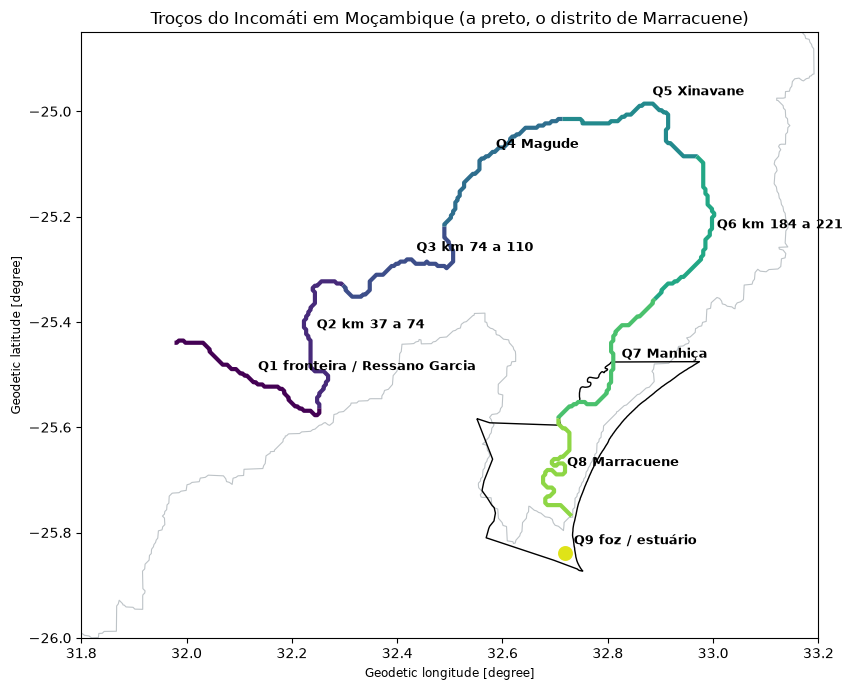

In [2]:
sections = module_q.load_sections(cfg)
lines = module_q.load_sections(cfg, "linhas")
basin = config.path(cfg, "interim", mkdir=False).parent / "raw" / "aoi" / "incomati_basin.geojson"
import geopandas as gpd
fig, ax = plt.subplots(figsize=(13, 7))
gpd.read_file(basin).boundary.plot(ax=ax, color="#bdc3c7", linewidth=0.8)
gpd.read_file(ROOT / "data" / "raw" / "aoi" / "marracuene_district.geojson").boundary.plot(ax=ax, color="black", linewidth=1)
colours = plt.cm.viridis(np.linspace(0, 0.95, len(sections)))
for (_, row), colour in zip(lines.iterrows(), colours):
    gpd.GeoSeries([row.geometry]).plot(ax=ax, color=colour, linewidth=3, markersize=60)
    point = row.geometry.interpolate(0.5, normalized=True) if row.geometry.geom_type == "LineString" else row.geometry
    ax.annotate(row["nome"], (point.x, point.y), xytext=(6, 6), textcoords="offset points", fontsize=9, fontweight="bold")
ax.set_xlim(31.8, 33.2); ax.set_ylim(-26.0, -24.85); ax.set_title("Troços do Incomáti em Moçambique (a preto, o distrito de Marracuene)")
plt.tight_layout(); plt.savefig(REPORTS / "29_trocos_do_rio.png", dpi=110)
sections.drop(columns="geometry")

## 2. Água pura e largura do rio

**Onde há água.** O mapa Dynamic World (10 m) diz, para cada píxel, em que parte
das imagens limpas de 2019 a 2025 havia água. Ficam os píxeis com água em pelo
menos 60 % das imagens, num corredor de 2,5 km à volta da linha do rio. As massas
de água arredondadas (lagoas, charcas) saem: o rio é comprido e estreito.

O mapa de água permanente do JRC (30 m), previsto no plano, foi experimentado
primeiro e quase não vê o rio a montante, que tem 50 a 80 m de largura.

**Água pura.** Em cada imagem só contam os píxeis de água que estão a pelo menos
um píxel de tudo o que não é água nesse dia (margens, areia, plantas). Assim a
margem acompanha o nível do rio.

**Largura.** Área de água a dividir pelo comprimento do troço. A regra do plano:
onde o rio tem menos de três píxeis Landsat de largura (90 m), só se usa o
Sentinel-2.

,nome,comprimento_km,largura_media_m,area_pura_sentinel2_ha,area_pura_landsat_ha,satelites
troco,,,,,,
Q1,Q1 fronteira / Ressano Garcia,36.800,48.800,113.900,35.600,só Sentinel-2 (2017+)
Q2,Q2 km 37 a 74,36.800,60.400,140.000,31.500,só Sentinel-2 (2017+)
Q3,Q3 km 74 a 110,36.800,79.900,200.600,49.600,só Sentinel-2 (2017+)
Q4,Q4 Magude,36.800,76.900,179.000,32.100,só Sentinel-2 (2017+)
Q5,Q5 Xinavane,36.800,52.300,118.500,26.900,só Sentinel-2 (2017+)
Q6,Q6 km 184 a 221,36.800,54.000,121.500,50.600,só Sentinel-2 (2017+)
Q7,Q7 Manhiça,36.800,138.800,378.400,171.500,Landsat (2006+) e Sentinel-2 (2017+)
Q8,Q8 Marracuene,36.800,354.700,"1,185.300",980.600,Landsat (2006+) e Sentinel-2 (2017+)
Q9,Q9 foz / estuário,NaN,NaN,"2,492.900","2,371.400",Landsat (2006+) e Sentinel-2 (2017+)


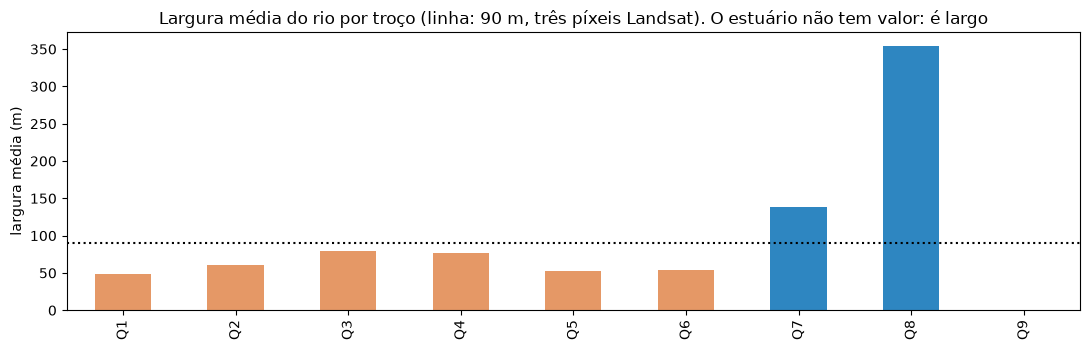

In [3]:
width = pd.read_csv(config.path(cfg, "sections", "largura_por_troco.csv", mkdir=False)).set_index("troco")
width["satelites"] = np.where(width["largura_media_m"].fillna(1000) >= Q.LANDSAT_MIN_WIDTH_M, "Landsat (2006+) e Sentinel-2 (2017+)", "só Sentinel-2 (2017+)")
ax = width["largura_media_m"].plot.bar(figsize=(11, 3.6), color=np.where(width["largura_media_m"].fillna(1000) >= Q.LANDSAT_MIN_WIDTH_M, "#2e86c1", "#e59866"))
ax.axhline(Q.LANDSAT_MIN_WIDTH_M, color="black", linestyle=":"); ax.set_ylabel("largura média (m)"); ax.set_xlabel("")
ax.set_title("Largura média do rio por troço (linha: 90 m, três píxeis Landsat). O estuário não tem valor: é largo")
plt.tight_layout(); plt.savefig(REPORTS / "29_largura_por_troco.png", dpi=110)
width[["nome", "comprimento_km", "largura_media_m", "area_pura_sentinel2_ha", "area_pura_landsat_ha", "satelites"]]

**Leitura.** Da fronteira até perto de Manhiça o rio é estreito de mais para o
Landsat: aí a série tem só os anos do Sentinel-2 (2017 em diante). Os 20 anos
completos existem nos três troços de jusante.

Isto é um limite real dos dados, e está previsto no plano. Não se preenche o
período em falta com estimativas.

A máscara é automática. Deve ser vista no QGIS por quem conhece o rio (camadas
`agua_permanente`, `agua_pura_sentinel2` e `agua_pura_landsat` do ficheiro
`trocos_rio.gpkg`).

## 3. As medições por imagem

dias                        pixeis_tipicos              \
satelite Landsat 5/7 Landsat 8/9 Sentinel-2    Landsat 5/7 Landsat 8/9   
troco                                                                    
Q1                15         134        417         45.000     148.000   
Q2                23         117        426         70.000     133.000   
Q3                19         156        458        131.000      50.000   
Q4                26          97        424        127.000     109.000   
Q5                83         237        773         48.000      81.000   
Q6                22         161        773         53.000     234.000   
Q7                61         212        857        203.000     374.000   
Q8                96         292        916      3,810.000   5,393.000   
Q9                98         303        910     14,768.000  19,161.000   

                      
satelite  Sentinel-2  
troco                 
Q1         1,336.000  
Q2         1,506.000  
Q3         2,242.000  
Q4           822.000  
Q5         1,229.000  
Q6         2,206.000  
Q7         7,272.000  
Q8        67,152.000  
Q9       190,351.000

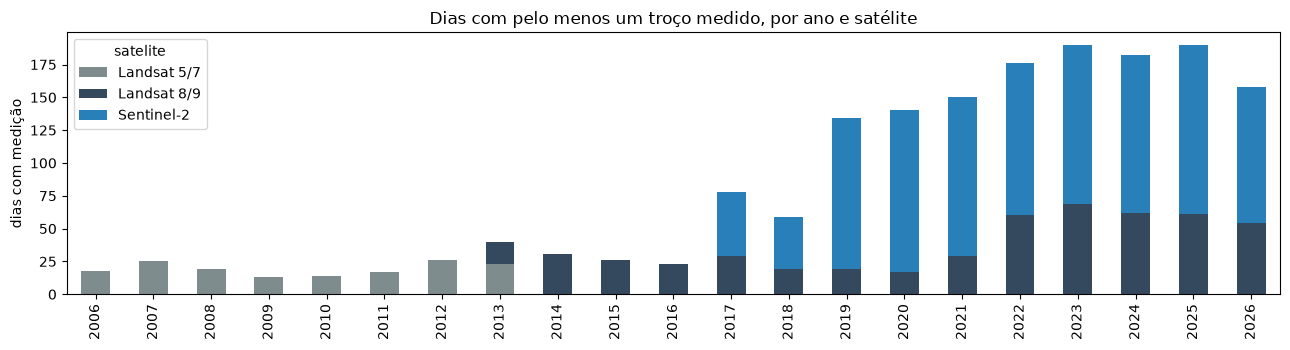

In [4]:
images = Q.load_images(cfg)
measured = images.dropna(subset=["ndti"])
names = {"landsat57": "Landsat 5/7", "landsat89": "Landsat 8/9", "sentinel2": "Sentinel-2"}
per_year = measured.assign(ano=measured["date"].dt.year, satelite=measured["sensor"].map(names)).groupby(["ano", "satelite"])["date"].nunique().unstack(fill_value=0)
ax = per_year.plot.bar(stacked=True, figsize=(13, 3.6), color=["#7f8c8d", "#34495e", "#2980b9"], ylabel="dias com medição")
ax.set_title("Dias com pelo menos um troço medido, por ano e satélite"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(REPORTS / "29_dias_com_medicao.png", dpi=110)
table = measured.assign(satelite=measured["sensor"].map(names)).groupby(["troco", "satelite"]).agg(dias=("date", "nunique"), pixeis_tipicos=("pixeis", "median")).unstack("satelite")
table.round(0)

**Leitura.** `pixeis_tipicos` é o número de píxeis de água pura numa imagem típica.
No Landsat, a montante, são poucas dezenas ou nenhum: confirma a regra da largura.

## 4. Os dois satélites concordam?

No mesmo dia e no mesmo troço, o Sentinel-2 e o Landsat 8/9 deviam dar o mesmo
valor. São instrumentos e correções atmosféricas independentes.

In [5]:
agreement = Q.cross_sensor(images)
agreement.round(3).to_csv(REPORTS / "29_concordancia_entre_satelites.csv")
display(agreement.round(2))
Q.section_reliability(images).to_frame("fiabilidade").T

,pares,r_ndti,dif_ndti,r_turbidez,fator_tipico_turbidez,razao_mediana_turbidez
troco,,,,,,
todos os troços,438,0.850,-0.000,0.850,1.560,0.880
Q1,29,0.890,0.030,0.900,1.270,1.030
Q2,22,0.880,0.010,0.900,1.290,0.940
Q3,31,0.150,-0.010,0.790,2.000,0.860
Q4,22,0.900,0.010,0.910,1.310,0.850
Q5,68,0.800,0.010,0.900,1.300,0.900
Q6,39,0.530,-0.020,0.640,1.910,0.930
Q7,62,0.750,-0.010,0.700,1.560,0.890
Q8,82,0.780,-0.010,0.740,1.580,0.870


troco,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9
fiabilidade,boa,boa,reduzida,boa,boa,reduzida,boa,boa,boa


**Como ler**

- `r_ndti`: correlação do índice de cor. Perto de 1 = os satélites concordam.
- `fator_tipico_turbidez`: por quanto diferem tipicamente as duas estimativas de
  turbidez. 1,5 quer dizer que uma pode ser 50 % maior do que a outra.

**Leitura.** No conjunto, o índice de cor (NDTI) é repetível. A turbidez em FNU
concorda menos: serve como ordem de grandeza, não como medição.

**Os troços não são todos iguais.** Onde a correlação do índice fica abaixo de
0,7, ou há menos de 15 pares, o troço fica marcado com **fiabilidade reduzida**
(tabela seguinte): os seus valores são mostrados, mas não dão origem a alertas.
A causa mais provável é a máscara de água apanhar coisas diferentes do rio
(bancos de areia, charcas), e é aí que a revisão no QGIS deve começar.

## 5. Parâmetros e tabela por troço e mês

| Parâmetro do plano | Como é calculado aqui | O que vale |
|---|---|---|
| Índice de cor (NDTI) | (vermelho − verde) / (vermelho + verde) | **base de todas as análises**; repetível entre satélites |
| Turbidez (FNU) | Dogliotti et al. (2015), banda do vermelho | estimativa sem calibração local |
| Sólidos suspensos (mg/L) | Nechad et al. (2010), banda do vermelho | estimativa; a mesma informação da turbidez |
| Transparência (Secchi, m) | relação ajustada às medições globais GLORIA | estimativa larga, até haver medições no rio |
| Clorofila-a (NDCI) | (B5 − B4) / (B5 + B4), só Sentinel-2 | **não reportada como clorofila**: no Incomáti segue o sedimento |
| Vegetação sobre a água | parte da água permanente com NDVI acima de 0,4 | fiável nos troços largos; a montante mistura a margem |
| Temperatura da água | banda térmica do Landsat (píxel de 100 m) | só nos troços com mais de 300 m de largura |

Os coeficientes dos algoritmos foram conferidos nos ficheiros distribuídos com o
ACOLITE. A versão de Dogliotti com a banda do infravermelho próximo foi rejeitada
no notebook 35 (os satélites não concordam); a do vermelho concorda melhor.

In [6]:
data = Q.monthly_dataset(cfg)
print(f"qualidade_trocos.parquet: {len(data):,} linhas = {data['troco'].nunique()} troços x {data['month'].nunique()} meses ({data['month'].min()} a {data['month'].max()})")
summary = data.groupby(["troco", "nome"]).agg(fonte=("fonte", lambda s: s[s != ""].mode().iloc[0] if (s != "").any() else ""), primeiro_mes=("month", lambda m: m[data.loc[m.index, "ndti"].notna()].min()),
                                               meses_com_cor=("ndti", "count"), meses_com_vegetacao=("vegetacao", "count"), meses_com_temperatura=("temp_c", "count"),
                                               turbidez_fnu_mediana=("turbidez_fnu", "median"), tss_mg_l_mediana=("tss_mg_l", "median"), secchi_m_mediana=("secchi_m", "median"))
summary["meses_sem_medicao_%"] = 100 * (1 - summary["meses_com_cor"] / data.groupby(["troco", "nome"])["month"].apply(lambda m: (m >= summary.loc[m.name, "primeiro_mes"]).sum()))
summary.round(1).to_csv(REPORTS / "29_resumo_do_dataset.csv")
summary.round(1)

qualidade_trocos.parquet: 2,250 linhas = 9 troços x 250 meses (2006-01 a 2026-10)


,,fonte,primeiro_mes,meses_com_cor,meses_com_vegetacao,meses_com_temperatura,turbidez_fnu_mediana,tss_mg_l_mediana,secchi_m_mediana,meses_sem_medicao_%
troco,nome,,,,,,,,,
Q1,Q1 fronteira / Ressano Garcia,Sentinel-2,2017-01,110,113,0,21.300,34.000,0.400,6.800
Q2,Q2 km 37 a 74,Sentinel-2,2017-01,110,112,0,23.400,37.100,0.400,6.800
Q3,Q3 km 74 a 110,Sentinel-2,2017-01,112,112,0,29.400,45.800,0.400,5.100
Q4,Q4 Magude,Sentinel-2,2017-01,108,110,0,20.400,32.800,0.400,8.500
Q5,Q5 Xinavane,Sentinel-2,2017-01,112,114,0,19.000,30.700,0.400,5.100
Q6,Q6 km 184 a 221,Sentinel-2,2017-01,114,116,0,8.900,15.400,0.700,3.400
Q7,Q7 Manhiça,Landsat,2006-01,159,210,0,16.200,23.300,0.500,36.400
Q8,Q8 Marracuene,Landsat,2006-01,200,206,200,16.400,23.400,0.500,20.000
Q9,Q9 foz / estuário,Landsat,2006-01,205,205,205,14.200,20.200,0.500,18.000


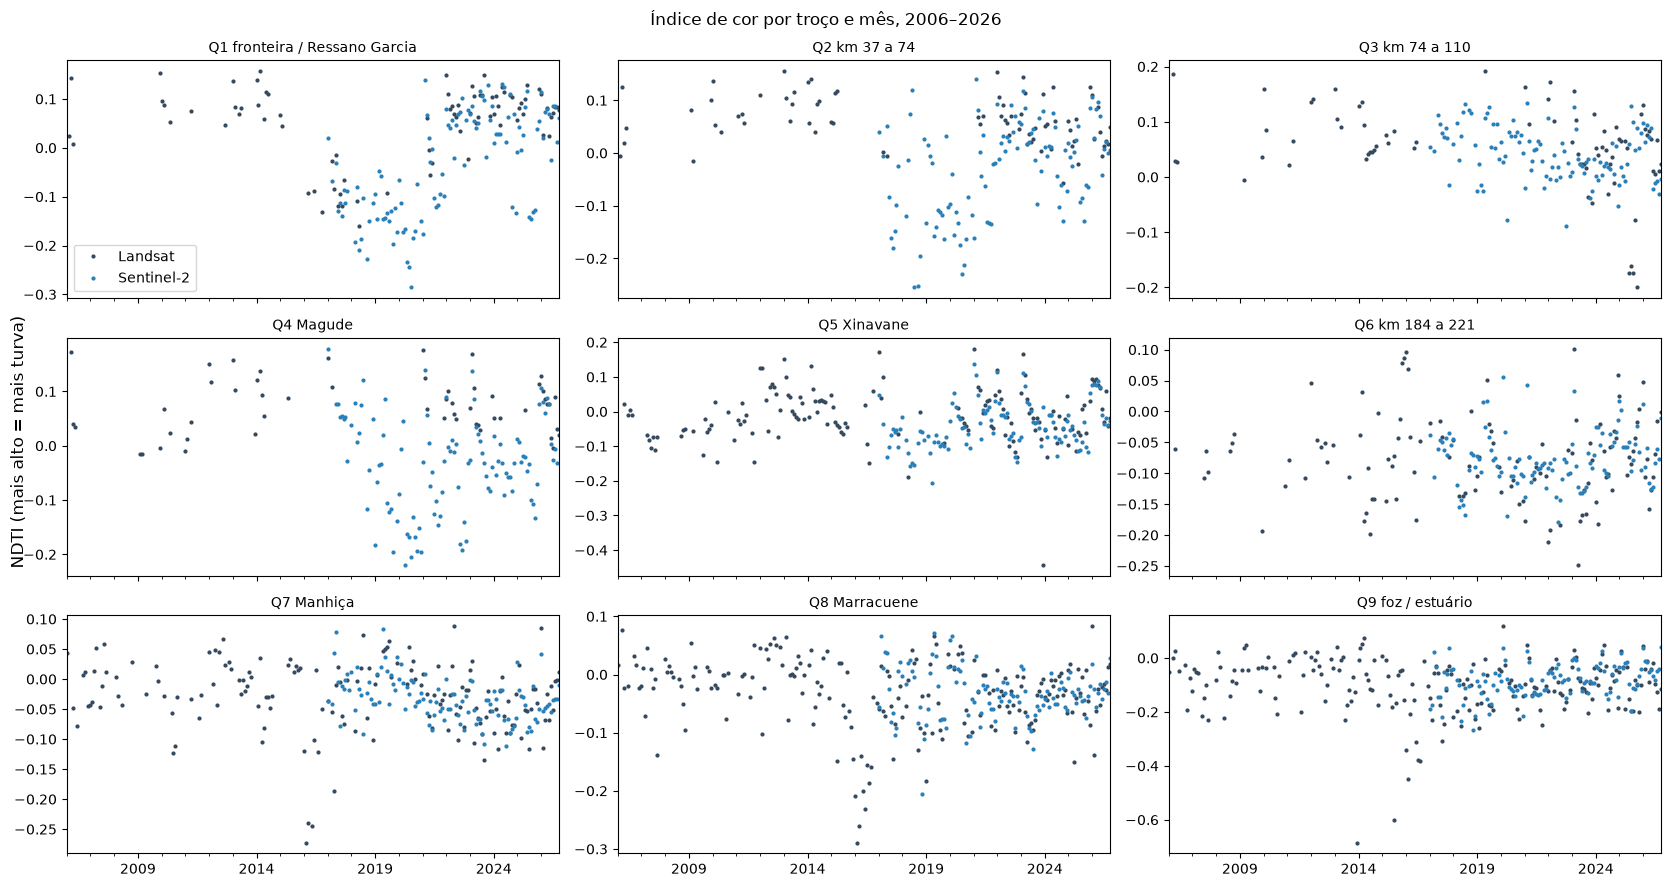

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(17, 9), sharex=True)
for ax, (section, group) in zip(axes.ravel(), data.groupby("troco")):
    series = group.set_index(pd.to_datetime(group["month"]))
    series["ndti_landsat"].plot(ax=ax, style=".", color="#34495e", markersize=4, label="Landsat")
    series["ndti_s2"].plot(ax=ax, style=".", color="#2980b9", markersize=4, label="Sentinel-2")
    ax.set_title(group["nome"].iloc[0], fontsize=10); ax.set_xlabel("")
axes[0, 0].legend(); fig.supylabel("NDTI (mais alto = mais turva)")
plt.suptitle("Índice de cor por troço e mês, 2006–2026"); plt.tight_layout(); plt.savefig(REPORTS / "29_series_por_troco.png", dpi=110)

**Leitura.** Cada ponto é a mediana das imagens limpas de um mês. Os meses sem
ponto não tiveram imagem limpa com água pura suficiente: ficam vazios (regra de
ouro do projecto, nunca inventar dados). A época das chuvas tem mais falhas,
porque há mais nuvens.

## Dicionário do ficheiro `qualidade_trocos.parquet`

| Coluna | Significado |
|---|---|
| `troco`, `nome`, `month` | troço (Q1 fronteira … Q9 foz) e mês |
| `ndti`, `turbidez_fnu`, `tss_mg_l`, `secchi_m`, `vegetacao` | valor do mês: do Landsat nos troços largos, do Sentinel-2 nos estreitos |
| `fonte` | de que satélite veio esse valor |
| `fiabilidade` | `boa` ou `reduzida`: os dois satélites concordam neste troço? |
| `…_landsat`, `…_s2` | o mesmo, separado por satélite |
| `ndci` | índice do Sentinel-2 (não é clorofila neste rio) |
| `temp_c` | temperatura da água, só troços largos |
| `n_imagens_landsat`, `n_imagens_s2` | imagens usadas no mês |
| `chuva_mm`, `caudal_m3s` (e `_m1`, `_m2`) | chuva na bacia e caudal em Marracuene no mês e nos dois anteriores |
| `ano`, `mes`, `epoca` | metadados de tempo |

## O que falta (para a equipa)

- **ACOLITE (tarefas W1-11 e W2-14).** A correção atmosférica própria para água não
  foi feita neste computador: exige descarregar imagens de nível 1 (cerca de 1 GB
  cada). Em sua vez, a repetibilidade foi testada com dois satélites (secção 4) e
  as fórmulas com o GLORIA (notebook 37).
- **Medições com disco de Secchi (W2-16, W3-08).** A equipa decidiu, a 12 de
  outubro de 2026, não fazer medições no local nesta fase. O Módulo Q fica, por
  isso, como um indicador relativo (a cor da água face ao seu normal), sem
  valores absolutos validados. O protocolo fica guardado em
  `docs/protocolo_de_campo_qualidade_da_agua.md` para uma fase futura.